# 02 - 2023 baseline: the data pipeline (steps 1-6)

This notebook **only calls** `baseline_2023.pipeline.build(...)`; all logic lives in `our_work/baseline_2023/pipeline.py`.
It builds the data three ways and shows what each step did:

| mode | what it is |
|---|---|
| `as_published` | the authors' notebook exactly, **including the column bug** |
| `as_published_fixed` | identical, but the column bug is fixed |
| `honest` | our corrected pipeline: held-out test set, 36 features, 1:1 balancing (the main benchmark) |

Audit findings referred to below: **F1** Dport removed | **F2** three text `Sport` values | **F3** `Unnamed: 0` index column | **F4** column-assignment bug | **F5** no test set | **F6** contiguous client chunks | **F7** per-client scaler on the unbalanced split | **F8** 2 normals per attack | **F9** unseeded sampling | **F10** no NaN/duplicate step | **F11** `array_split` on a DataFrame.
No model is trained here (that is step 7+).

In [1]:
import sys, pathlib, subprocess
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 200, "display.max_columns", 30, "display.max_colwidth", 80)

ROOT = pathlib.Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent                      # our_work/
sys.path.insert(0, str(ROOT))
from baseline_2023.pipeline import build

N_CLIENTS = 15
R = {
    "as_published":       build("as_published", N_CLIENTS),
    "as_published_fixed": build("as_published_fixed", N_CLIENTS),
    "honest":             build("honest", N_CLIENTS),
}
print({m: r["info"]["effective_args"] for m, r in R.items()})

{'as_published': {'n_clients': 15, 'seed': 0, 'keep_dport': False, 'balance_ratio': 2, 'partition': 'contiguous'}, 'as_published_fixed': {'n_clients': 15, 'seed': 0, 'keep_dport': False, 'balance_ratio': 2, 'partition': 'contiguous'}, 'honest': {'n_clients': 15, 'seed': 0, 'keep_dport': True, 'balance_ratio': 1, 'partition': 'iid'}}


## Step 1 - Data
Loads the public WUSTL-EHMS-2020 CSV and asserts it is exactly the file the paper describes (16,318 rows, 45 columns, 14,272 normal / 2,046 attack).
`Attack Category` is pulled out into a separate array (`cat_*`); it is **never** an input feature.
**F2:** three rows have *text* in `Sport` (`dircproxy`, `fido`, `tfido`), all normal.

In [2]:
raw = R["honest"]["info"]["raw"]
print("shape:", raw["shape"], "| labels:", raw["labels"], "| categories:", raw["categories"])
pd.DataFrame(raw["sport_text_rows"])

shape: (16318, 45) | labels: {0: 14272, 1: 2046} | categories: {'normal': 14272, 'Spoofing': 1124, 'Data Alteration': 922}


,row,value,label,category
0,7923,dircproxy,0,normal
1,8412,fido,0,normal
2,10633,tfido,0,normal


## Step 2 - Cleaning
Drops the identifier columns and `Attack Category`. **F1:** the authors' file also lacks `Dport` (35 features instead of the paper's 36).
**F2:** `as_published` converts the 3 text `Sport` values to 0 and keeps all 16,318 rows (an *assumption*: that step is not in their notebook); `honest` drops those 3 rows.
**F3:** `as_published*` carry the `Unnamed: 0` row-index column their CSV had; `honest` never creates it.
**F10:** `honest` runs `dropna` / `drop_duplicates` and asserts both remove 0 rows (the notebook has no such step).

In [3]:
rows = []
for m, r in R.items():
    i = r["info"]
    rows.append({"mode": m, "rows after cleaning": i["rows"]["after_clean"], "features kept": i["n_features"],
                 "Dport kept": "Dport" in i["features_kept"], "Unnamed: 0 present": "Unnamed: 0" in i["columns_after_cleaning"],
                 "Sport handling": i["sport"]["handling"], "dropna/dups removed": i["clean"]})
display(pd.DataFrame(rows).set_index("mode").T)
print("as_published columns after cleaning (%d):" % len(R["as_published"]["info"]["columns_after_cleaning"]))
print(R["as_published"]["info"]["columns_after_cleaning"])
cc = R["honest"]["info"]["constant_columns"]
print("\nConstant columns (one value in every row, carry NO information; reported only, NOT dropped):")
display(pd.DataFrame({"column": cc["columns"], "value": [cc["values"][c] for c in cc["columns"]]}))
print("as_published: constant columns kept:", R["as_published"]["info"]["constant_columns"]["columns"],
      "| removed by the authors:", R["as_published"]["info"]["constant_columns"]["removed_before_modelling"])

mode,as_published,as_published_fixed,honest
rows after cleaning,16318,16318,16315
features kept,35,35,36
Dport kept,False,False,True
Unnamed: 0 present,True,True,False
Sport handling,"coerced to numeric, 3 text values filled with 0, rows kept","coerced to numeric, 3 text values filled with 0, rows kept","coerced to numeric, rows dropped"
dropna/dups removed,None,None,"{'dropna_removed': 0, 'drop_duplicates_removed': 0}"


as_published columns after cleaning (37):
['Unnamed: 0', 'Sport', 'SrcBytes', 'DstBytes', 'SrcLoad', 'DstLoad', 'SrcGap', 'DstGap', 'SIntPkt', 'DIntPkt', 'SIntPktAct', 'DIntPktAct', 'SrcJitter', 'DstJitter', 'sMaxPktSz', 'dMaxPktSz', 'sMinPktSz', 'dMinPktSz', 'Dur', 'Trans', 'TotPkts', 'TotBytes', 'Load', 'Loss', 'pLoss', 'pSrcLoss', 'pDstLoss', 'Rate', 'Temp', 'SpO2', 'Pulse_Rate', 'SYS', 'DIA', 'Heart_rate', 'Resp_Rate', 'ST', 'Label']

Constant columns (one value in every row, carry NO information; reported only, NOT dropped):


,column,value
0,Dport,1111.0
1,SrcGap,0.0
2,DstGap,0.0
3,DIntPktAct,0.0
4,dMinPktSz,60.0
5,Trans,1.0


as_published: constant columns kept: ['SrcGap', 'DstGap', 'DIntPktAct', 'dMinPktSz', 'Trans'] | removed by the authors: ['Dport']


**Forced arguments.** `as_published*` always use `keep_dport=False`, `balance_ratio=2`, `partition='contiguous'` (what the authors did).
If you explicitly pass something else, it is overridden **with a printed warning** (not silently). Passing nothing, or the authors' values, is silent.

In [4]:
import warnings
with warnings.catch_warnings(record=True) as w:
    warnings.simplefilter("always")
    _ = build("as_published", N_CLIENTS, keep_dport=True, balance_ratio=1, partition="iid")
print("WARNING:", [str(x.message) for x in w if "OVERRIDDEN" in str(x.message)][0])
print("recorded in info:", _["info"]["overridden_args"])

recorded in info: [{'arg': 'keep_dport', 'passed': True, 'used': False}, {'arg': 'balance_ratio', 'passed': 1, 'used': 2}, {'arg': 'partition', 'passed': 'iid', 'used': 'contiguous'}]


## Step 3 - Splitting
**F5:** the authors have **no held-out test set**; each client is split 90/10 in step 4 and the pooled 10% slices are their reported evaluation.
`honest` holds out a stratified 20% **test set first** (seed 42), then takes 15% of the rest as validation. Test and validation are identical for every seed and client count.

In [5]:
sp = R["honest"]["info"]["split"]
pd.DataFrame({k: {"rows": sp[k]["rows"], "attacks": sp[k]["attacks"], "attack share": round(sp[k]["attack_share"], 4),
                  "Spoofing": sp[k]["categories"]["Spoofing"], "Data Alteration": sp[k]["categories"]["Data Alteration"]}
              for k in ("train", "val", "test")}).T

,rows,attacks,attack share,Spoofing,Data Alteration
train,11094.0,1391.0,0.1254,788.0,603.0
val,1958.0,246.0,0.1256,137.0,109.0
test,3263.0,409.0,0.1253,199.0,210.0


## Step 4 - Federated partition
**F6 / F11:** `as_published*` cut the file into **contiguous chunks** with `np.array_split` on row positions, shuffle each chunk (`random_state=13`) and split it 90/10 (`random_state=1337`).
`honest` shares out only the **training part** (IID, seeded); validation stays global and no client ever touches the test set.

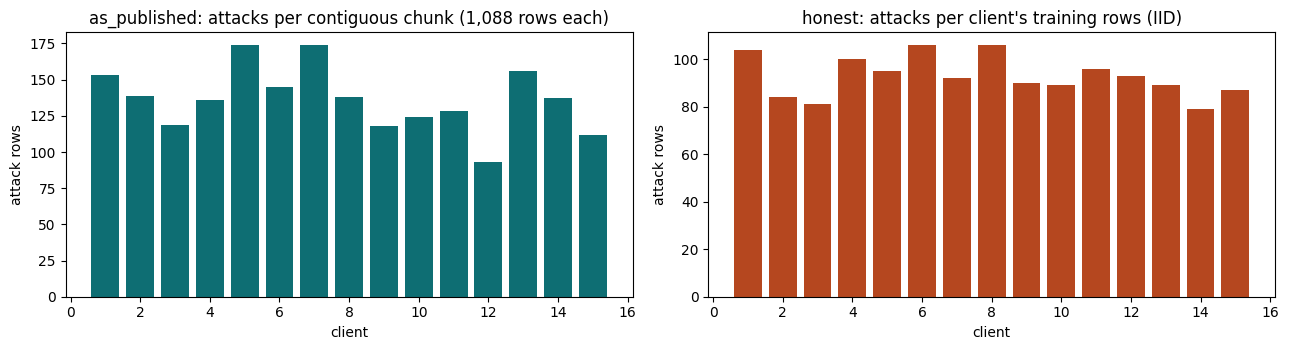

,as_published chunk rows,chunk attacks,train rows,val rows,honest train rows,honest attacks
1,1088,153,979,109,740,104
2,1088,139,979,109,740,84
3,1088,119,979,109,740,81
4,1088,136,979,109,740,100
5,1088,174,979,109,740,95
6,1088,145,979,109,740,106
7,1088,174,979,109,740,92
8,1088,138,979,109,740,106
9,1088,118,979,109,740,90
10,1088,124,979,109,739,89


client 1 first five 'Unnamed: 0' after the shuffle: [248, 204, 142, 472, 370] (authors' notebook: 248, 204, 142, 472, 370)


In [6]:
ap = R["as_published"]["info"]["clients"]
ho = R["honest"]["info"]["clients"]
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6), sharey=False)
x = np.arange(1, N_CLIENTS + 1)
ax[0].bar(x, [c["chunk"]["attacks"] for c in ap], color="#0E6E73")
ax[0].set_title("as_published: attacks per contiguous chunk (1,088 rows each)")
ax[1].bar(x, [c["train"]["attacks"] for c in ho], color="#B5471F")
ax[1].set_title("honest: attacks per client's training rows (IID)")
for a in ax: a.set_xlabel("client"); a.set_ylabel("attack rows")
plt.tight_layout(); plt.show()
tbl = pd.DataFrame({"as_published chunk rows": [c["chunk"]["rows"] for c in ap],
                    "chunk attacks": [c["chunk"]["attacks"] for c in ap],
                    "train rows": [c["train"]["rows"] for c in ap], "val rows": [c["val"]["rows"] for c in ap],
                    "honest train rows": [c["train"]["rows"] for c in ho], "honest attacks": [c["train"]["attacks"] for c in ho]},
                   index=x)
display(tbl)
print("client 1 first five 'Unnamed: 0' after the shuffle:", ap[0]["shuffled_head_row_numbers"], "(authors' notebook: 248, 204, 142, 472, 370)")

## Step 5 - Scaling
**F7.** `as_published*`: one `StandardScaler` **per client**, fitted on that client's **unbalanced** training rows (as the authors).
`honest`: **ONE global scaler** (aggregate mean/variance shared across clients), fitted on the union of all clients' unbalanced training rows and applied to every client's training rows **and** to the global validation and test sets, so training and evaluation use the same scale.
**F4 (the column bug):** the authors write `train_df[train_df.columns.difference(['Label'])] = scaled_values`. `.difference()` returns the names *sorted*, the scaled values are in *file order*, so every column is written under another column's name:
scaled `Temp` lands in `Unnamed: 0` (then dropped, so temperature is lost) and the scaled row index lands in `DIA`.
`as_published_fixed` and `honest` assign by one explicit column list. Everything is verified **by value** (correlation with the raw column), not by name.

In [7]:
bug = R["as_published"]["info"]["column_bug"]
print("lost feature:", bug["lost_feature"], "| column that holds the row index:", bug["row_index_in_column"])
cm = pd.DataFrame({"column NAME": list(bug["column_content_map"]), "holds the scaled values of": list(bug["column_content_map"].values())})
display(cm[cm["column NAME"] != cm["holds the scaled values of"]].head(8))
rows = []
for m, r in R.items():
    v = r["info"]["scaling"]
    b = r["info"].get("column_bug")                      # only present when the bug is reproduced
    rows.append({"mode": m, "scalers": v["n_scalers"], "model inputs": v["inputs"], "column bug reproduced": v["column_bug_reproduced"],
                 "Temp is an input": not (b and b["lost_feature"] == "Temp"),
                 "row index is an input": bool(b)})
display(pd.DataFrame(rows).set_index("mode"))
print("honest:", R["honest"]["info"]["scaling"]["scaler"])

lost feature: Temp | column that holds the row index: DIA


,column NAME,holds the scaled values of
0,DIA,Unnamed: 0
1,DIntPkt,Sport
2,DIntPktAct,SrcBytes
4,DstGap,SrcLoad
5,DstJitter,DstLoad
6,DstLoad,SrcGap
7,Dur,DstGap
8,Heart_rate,SIntPkt


,scalers,model inputs,column bug reproduced,Temp is an input,row index is an input
mode,,,,,
as_published,15,35,True,False,True
as_published_fixed,15,35,False,True,False
honest,1,36,False,True,False


honest: ONE global StandardScaler fitted on the union of all clients' unbalanced training rows; applied to every client's training rows and to the global validation and test sets


## Step 6 - Balancing (training rows only)
**F8:** the authors keep **2 normals per attack** (33% attacks); `honest` defaults to 1:1. **F9:** their `random.sample` is unseeded, so their exact subsets cannot be recovered; we use `RandomState(seed + client_index)`.
Validation and test are **never** balanced.

In [8]:
rows = []
for m, r in R.items():
    cl = r["clients"]
    ntr = sum(len(c["y_train"]) for c in cl); natt = sum(c["n_attack_train"] for c in cl)
    rows.append({"mode": m, "balanced train rows": ntr, "attacks": natt, "normals": ntr - natt, "attack share in train": round(natt / ntr, 3)})
display(pd.DataFrame(rows).set_index("mode"))
print("authors' notebook, 15 clients: 5,493 balanced training examples per round ->", sum(len(c["y_train"]) for c in R["as_published"]["clients"]))

,balanced train rows,attacks,normals,attack share in train
mode,,,,
as_published,5493,1831,3662,0.333
as_published_fixed,5493,1831,3662,0.333
honest,2782,1391,1391,0.500


authors' notebook, 15 clients: 5,493 balanced training examples per round -> 5493


## Evaluation sets and the majority-class baseline
A model that always answers "normal" scores the *majority accuracy* below, so accuracy alone says little.

In [9]:
rows = []
for m, r in R.items():
    for k, s in r["info"]["eval_sets"].items():
        rows.append({"mode": m, "set": k, "rows": s["rows"], "attacks": s["attacks"], "attack share": round(s["attack_share"], 4),
                     "always-normal accuracy": round(s["majority_acc"], 4)})
display(pd.DataFrame(rows).set_index(["mode", "set"]))
print("as_published has no test set: its 'val' is the pooled per-client 10% slices (the authors' reported evaluation).")
print("honest per-category counts in the test set:", dict(zip(*np.unique(R["honest"]["cat_test"], return_counts=True))))

rows  attacks  attack share  always-normal accuracy
mode               set                                                      
as_published       val   1635      215        0.1315                  0.8685
as_published_fixed val   1635      215        0.1315                  0.8685
honest             val   1958      246        0.1256                  0.8744
                   test  3263      409        0.1253                  0.8747

as_published has no test set: its 'val' is the pooled per-client 10% slices (the authors' reported evaluation).
honest per-category counts in the test set: {'Data Alteration': np.int64(210), 'Spoofing': np.int64(199), 'normal': np.int64(2854)}


## Acceptance checks
`python -m baseline_2023.audit.check_pipeline` (run from `our_work/`). The 10- and 5-client `as_published` lines are **report only**.

In [10]:
res = subprocess.run([sys.executable, "-m", "baseline_2023.audit.check_pipeline"], cwd=ROOT, capture_output=True, text=True)
print("\n".join(l for l in res.stdout.splitlines() if "arn" not in l))
print("exit code:", res.returncode)

[PASS] S1 public file shape: (16318, 45)
[PASS] S1 column order is the public order: 45 columns
[PASS] S1 Label counts: {0: 14272, 1: 2046}
[PASS] S1 Attack Category counts: {'normal': 14272, 'Spoofing': 1124, 'Data Alteration': 922}
[PASS] S1 3 text values in Sport, rows 7923/8412/10633, all normal: [(7923, 'dircproxy', 0), (8412, 'fido', 0), (10633, 'tfido', 0)]
[PASS] S1 Attack Category carried separately, aligned with rows: 16318 values
[PASS] S2 as_published: 37 columns in the authors' order: 37 columns; Dport present=False
[PASS] S2 as_published: 16,318 rows kept: 16318 rows
[PASS] S2 as_published: Unnamed: 0 is the 0-based row position: 0..16317
[PASS] S2 as_published: first five Sport values: [58059, 58062, 58065, 58067, 58069]
[PASS] S2 as_published: first five SrcLoad values: [276914, 230984, 218470, 203376, 235723]
[PASS] S2 as_published: the 3 text Sport rows are filled with 0: [0.0, 0.0, 0.0]
[PASS] S2 as_published: no NaN, all numeric
[PASS] S2 honest: 16,315 rows (3 text